In [1]:
# CP322 Assignment 1 — k-Nearest Neighbours from scratch
# Dataset: 8x8 grids of pixel counts (64 features), labels are digits 4 and 9.

import numpy as np  # pyright: ignore[reportMissingImports]
import pandas as pd # pyright: ignore[reportMissingImports]
import matplotlib.pyplot as plt # pyright: ignore[reportMissingImports]

# Load the data (pandas is used only for reading the CSVs)
train_df = pd.read_csv("knn-dataset/train.csv")
test_df = pd.read_csv("knn-dataset/test.csv")

# Last column is the class label, first 64 columns are the pixel-count features
X_train = train_df.iloc[:, :-1].to_numpy(dtype=float)
y_train = train_df.iloc[:, -1].to_numpy()
X_test = test_df.iloc[:, :-1].to_numpy(dtype=float)
y_test = test_df.iloc[:, -1].to_numpy()

print("Training set:", X_train.shape, " labels:", np.unique(y_train))
print("Test set:    ", X_test.shape, " labels:", np.unique(y_test))

Matplotlib is building the font cache; this may take a moment.


Training set: (904, 64)  labels: [4 9]
Test set:     (226, 64)  labels: [4 9]


In [2]:
# ---------- Part 1: KNN implemented from scratch ----------

def euclidean_distance(a, b):
    """Euclidean distance between two points, written out explicitly:
    sqrt( sum_i (a_i - b_i)^2 ).
    numpy is used only for the element-wise arithmetic."""
    diff = a - b
    return np.sqrt(np.sum(diff ** 2))


def majority_vote(labels):
    """Return the label that appears most often among the neighbours.
    `labels` must be ordered from nearest to farthest neighbour.
    Ties are broken by dropping the farthest neighbour and re-voting,
    which is guaranteed to terminate (k=1 can never tie)."""
    labels = list(labels)
    while True:
        counts = {}
        for lab in labels:
            counts[lab] = counts.get(lab, 0) + 1
        best_count = max(counts.values())
        winners = [lab for lab, c in counts.items() if c == best_count]
        if len(winners) == 1:
            return winners[0]
        labels = labels[:-1]  # tie -> remove farthest neighbour and re-vote


def knn_predict_one(x, X_ref, y_ref, k):
    """Predict the label of a single point x using the k nearest
    neighbours in the reference set (X_ref, y_ref)."""
    # distance from x to every reference point (same formula as
    # euclidean_distance, vectorised over all rows for speed)
    dists = np.sqrt(np.sum((X_ref - x) ** 2, axis=1))
    nearest_idx = np.argsort(dists)[:k]  # indices of k smallest distances
    return majority_vote(y_ref[nearest_idx])


def knn_predict(X_query, X_ref, y_ref, k):
    """Predict labels for every row of X_query."""
    return np.array([knn_predict_one(x, X_ref, y_ref, k) for x in X_query])


def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


# quick check of the distance function against a hand computation
assert euclidean_distance(np.array([0.0, 3.0]), np.array([4.0, 0.0])) == 5.0
print("Distance function sanity check passed.")

Distance function sanity check passed.


In [3]:
# ---------- Part 2: 10-fold cross-validation on the training set only ----------
# The test set is NOT touched anywhere in this cell.

N_FOLDS = 10
K_VALUES = range(1, 31)
rng = np.random.default_rng(seed=42)

# Shuffle the training indices once, then split them into 10 folds
shuffled_idx = rng.permutation(len(X_train))
folds = np.array_split(shuffled_idx, N_FOLDS)

cv_accuracies = {}  # k -> average validation accuracy across the 10 folds

for k in K_VALUES:
    fold_accs = []
    for i in range(N_FOLDS):
        val_idx = folds[i]
        trn_idx = np.concatenate([folds[j] for j in range(N_FOLDS) if j != i])

        X_trn, y_trn = X_train[trn_idx], y_train[trn_idx]
        X_val, y_val = X_train[val_idx], y_train[val_idx]

        y_pred = knn_predict(X_val, X_trn, y_trn, k)
        fold_accs.append(accuracy(y_val, y_pred))
    cv_accuracies[k] = np.mean(fold_accs)
    print(f"k = {k:2d}   average CV accuracy = {cv_accuracies[k]:.4f}")

k =  1   average CV accuracy = 0.9933
k =  2   average CV accuracy = 0.9933
k =  3   average CV accuracy = 0.9967


k =  4   average CV accuracy = 0.9967


k =  5   average CV accuracy = 0.9967
k =  6   average CV accuracy = 0.9967
k =  7   average CV accuracy = 0.9923


k =  8   average CV accuracy = 0.9923


k =  9   average CV accuracy = 0.9934
k = 10   average CV accuracy = 0.9934
k = 11   average CV accuracy = 0.9945


k = 12   average CV accuracy = 0.9945


... (5 outputs left out)

k = 24   average CV accuracy = 0.9934


k = 25   average CV accuracy = 0.9934
k = 26   average CV accuracy = 0.9934
k = 27   average CV accuracy = 0.9923


k = 28   average CV accuracy = 0.9923


k = 29   average CV accuracy = 0.9934
k = 30   average CV accuracy = 0.9934


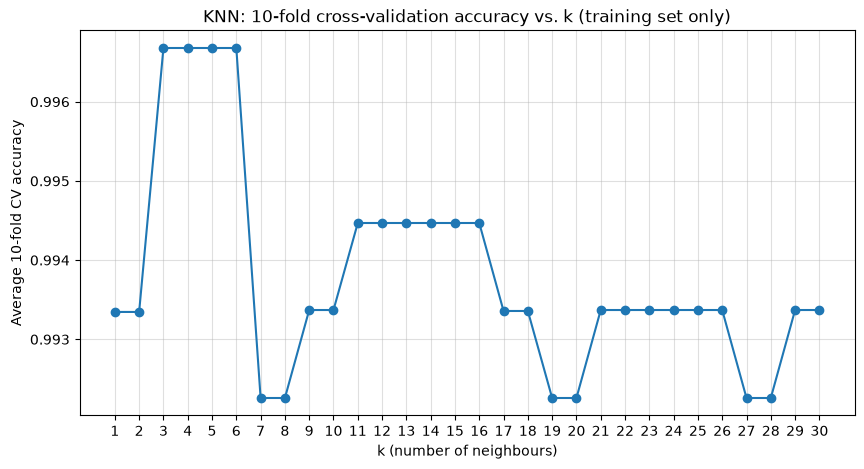

In [4]:
# ---------- Plot: average cross-validation accuracy vs. k ----------

ks = list(cv_accuracies.keys())
accs = [cv_accuracies[k] for k in ks]

plt.figure(figsize=(10, 5))
plt.plot(ks, accs, marker="o")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Average 10-fold CV accuracy")
plt.title("KNN: 10-fold cross-validation accuracy vs. k (training set only)")
plt.xticks(ks)
plt.grid(True, alpha=0.4)
plt.show()

In [5]:
# ---------- Part 3: best k and its cross-validation accuracy ----------
# If several k tie on CV accuracy, prefer the smallest one.

best_k = max(cv_accuracies, key=lambda k: (cv_accuracies[k], -k))
print(f"Best k found by 10-fold cross-validation: k = {best_k}")
print(f"Cross-validation accuracy at k = {best_k}: {cv_accuracies[best_k]:.4f}")

Best k found by 10-fold cross-validation: k = 3
Cross-validation accuracy at k = 3: 0.9967


In [6]:
# ---------- Part 4: final evaluation on the held-out test set ----------
# KNN has no explicit training step, so "retraining on the full training set"
# simply means using ALL 904 training examples as the reference set.
# This is the only place the test set is used.

y_test_pred = knn_predict(X_test, X_train, y_train, best_k)
test_acc = accuracy(y_test, y_test_pred)

print(f"Test accuracy with k = {best_k}: {test_acc:.4f} "
      f"({int(test_acc * len(y_test))}/{len(y_test)} correct)")

Test accuracy with k = 3: 0.9956 (225/226 correct)
